In [3]:
# ===== 노트북 설정: bandit.py 수정 시 자동 반영, src 폴더 경로 추가 =====
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import polars as pl

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT / "src"))
from bandit import FeatureBuilder

# ===== 데이터 로딩 및 정리 (EDA와 동일한 규칙) =====
CAMPAIGN = "men"
DATA_DIR = PROJECT_ROOT / "data"
random_dir = DATA_DIR / "random" / CAMPAIGN

random_log_df = (
    pl.read_csv(random_dir / f"{CAMPAIGN}.csv")
    .drop("")
    .with_columns(pl.col("timestamp").str.to_datetime(format="%Y-%m-%d %H:%M:%S%.f%:z"))
    .unique(maintain_order=True)  # 중복 행 제거
)
item_df = pl.read_csv(random_dir / "item_context.csv").drop("")
print(f"random 로그: {random_log_df.height:,}행 / 아이템: {item_df.height}개")

# ===== 피처 구성기 학습 =====
feature_builder = FeatureBuilder().fit(random_log_df, item_df)

# ===== 확인 1: 차원 =====
print("\n[차원]")
print(f"사용자 피처: {feature_builder.n_user_dims} / 아이템 피처: {feature_builder.n_item_dims} "
      f"/ 전체: {feature_builder.n_dims}")
for feature_col, categories in feature_builder.user_categories.items():
    print(f"  {feature_col}: {len(categories) - 1}개 + 기타")

# ===== 확인 2: 상호작용 대상 범주 =====
user_matrix, interaction_flags = feature_builder.transform_users(random_log_df)
print("\n[상호작용 대상]")
print(f"해시값 앞부분: {feature_builder.interaction_category[:12]}")
print(f"해당 행 비율: {interaction_flags.mean():.2%}")

# ===== 확인 3: 사용자 원-핫 (행마다 피처 4개 → 합이 정확히 4) =====
row_sums = user_matrix.sum(axis=1)
print("\n[사용자 원-핫]")
print(f"행별 합계 고유값: {np.unique(row_sums)}")
print(f"'기타'로 묶인 행 비율: "
      f"{user_matrix[:, [idx for idx, name in enumerate(feature_builder.user_feature_names) if name.endswith('=other')]].sum(axis=1).astype(bool).mean():.2%}")

# ===== 확인 4: 아이템 피처 행렬 =====
print("\n[아이템 피처 행렬]")
print(f"shape: {feature_builder.item_matrix.shape}")
print(f"고유한 행 수 (피처 조합이 다른 아이템 수): {np.unique(feature_builder.item_matrix, axis=0).shape[0]}")
print(f"item_feature_0 평균/표준편차: {feature_builder.item_matrix[:, 0].mean():.3f} / "
      f"{feature_builder.item_matrix[:, 0].std():.3f}")

# ===== 확인 5: 후보 행렬 (uf0_1 사용자 1명, 아닌 사용자 1명) =====
flagged_row = int(np.argmax(interaction_flags == 1))
unflagged_row = int(np.argmax(interaction_flags == 0))
flagged_candidates = feature_builder.build_candidates(user_matrix[flagged_row], interaction_flags[flagged_row])
unflagged_candidates = feature_builder.build_candidates(user_matrix[unflagged_row], interaction_flags[unflagged_row])

interaction_start = feature_builder.n_user_dims + feature_builder.n_item_dims
print("\n[후보 행렬]")
print(f"shape: {flagged_candidates.shape}")
print(f"uf0_1 사용자 → 상호작용 구간 = 아이템 피처: "
      f"{np.array_equal(flagged_candidates[:, interaction_start:], feature_builder.item_matrix)}")
print(f"그 외 사용자 → 상호작용 구간 전부 0: "
      f"{np.all(unflagged_candidates[:, interaction_start:] == 0)}")

random 로그: 452,868행 / 아이템: 34개

[차원]
사용자 피처: 26 / 아이템 피처: 28 / 전체: 82
  user_feature_0: 3개 + 기타
  user_feature_1: 4개 + 기타
  user_feature_2: 8개 + 기타
  user_feature_3: 7개 + 기타

[상호작용 대상]
해시값 앞부분: 1a2b2ad3a7f2
해당 행 비율: 29.21%

[사용자 원-핫]
행별 합계 고유값: [4.]
'기타'로 묶인 행 비율: 0.98%

[아이템 피처 행렬]
shape: (34, 28)
고유한 행 수 (피처 조합이 다른 아이템 수): 33
item_feature_0 평균/표준편차: -0.000 / 1.000

[후보 행렬]
shape: (34, 82)
uf0_1 사용자 → 상호작용 구간 = 아이템 피처: True
그 외 사용자 → 상호작용 구간 전부 0: True


Random      : 0.5초 (23µs/라운드)
BernoulliTS : 0.7초 (34µs/라운드)
LinTS       : 8.5초 (423µs/라운드)

[마지막 5,000라운드 평균 클릭 확률]  최적(정답을 아는 경우): 0.1452
Random      : 0.0617 (최적 대비 42.5%)
BernoulliTS : 0.1372 (최적 대비 94.5%)
LinTS       : 0.1264 (최적 대비 87.0%)


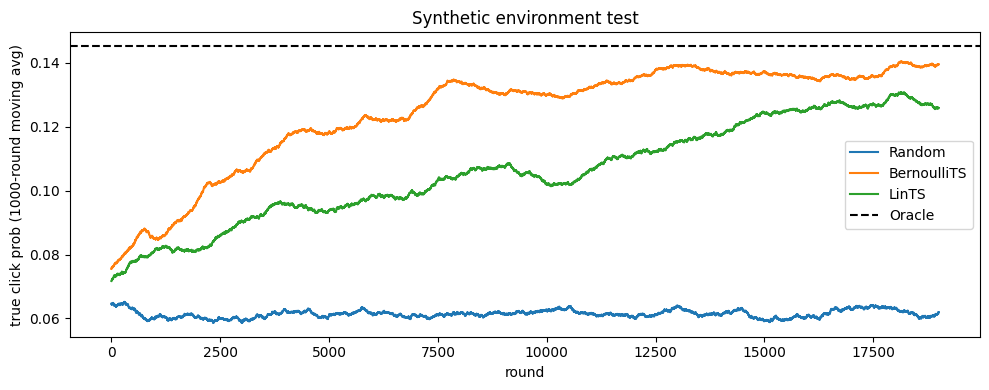

In [4]:
import numpy as np
import time
import matplotlib.pyplot as plt
from bandit import RandomPolicy, BernoulliTS, LinTS

# ===== 테스트 설정 =====
TEST_SEED = 0
N_TEST_ROUNDS = 20_000
BASE_CTR = 0.05
test_rng = np.random.default_rng(TEST_SEED)

# ===== 가상 환경: 정답 가중치 (아이템·상호작용 구간에만 값 → 그룹별 최적 아이템이 달라짐) =====
true_theta = np.zeros(feature_builder.n_dims)
true_theta[feature_builder.n_user_dims:] = test_rng.normal(0, 0.03, size=2 * feature_builder.n_item_dims)

def true_click_probs(candidate_matrix: np.ndarray) -> np.ndarray:
    return np.clip(BASE_CTR + candidate_matrix @ true_theta, 0.001, 0.999)

# ===== 모든 정책이 같은 사용자 순서·같은 난수로 테스트되도록 미리 생성 =====
sampled_rows = test_rng.integers(user_matrix.shape[0], size=N_TEST_ROUNDS)
reward_uniforms = test_rng.random(N_TEST_ROUNDS)

# ===== 정책 하나를 가상 환경에서 온라인 실행 =====
def run_synthetic(policy):
    chosen_true_probs = np.zeros(N_TEST_ROUNDS)
    best_true_probs = np.zeros(N_TEST_ROUNDS)
    for round_idx, row_idx in enumerate(sampled_rows):
        candidates = feature_builder.build_candidates(user_matrix[row_idx], interaction_flags[row_idx])
        click_probs = true_click_probs(candidates)
        context = candidates if policy.uses_context else None

        chosen_item = policy.select(context)
        reward = float(reward_uniforms[round_idx] < click_probs[chosen_item])
        policy.update(context, chosen_item, reward)

        chosen_true_probs[round_idx] = click_probs[chosen_item]
        best_true_probs[round_idx] = click_probs.max()
    return chosen_true_probs, best_true_probs

# ===== 세 정책 실행 및 소요 시간 측정 =====
n_items = feature_builder.n_items
test_policies = {
    "Random": RandomPolicy(n_items, seed=1),
    "BernoulliTS": BernoulliTS(n_items, seed=1),
    "LinTS": LinTS(n_items, feature_builder.n_dims, exploration_scale=0.5, seed=1),
}
test_results = {}
for policy_name, policy in test_policies.items():
    start_time = time.perf_counter()
    test_results[policy_name] = run_synthetic(policy)
    elapsed = time.perf_counter() - start_time
    print(f"{policy_name:12s}: {elapsed:.1f}초 ({elapsed / N_TEST_ROUNDS * 1e6:.0f}µs/라운드)")

# ===== 결과 요약: 마지막 5,000라운드의 평균 실제 클릭 확률 =====
oracle_ctr = test_results["Random"][1][-5000:].mean()
print(f"\n[마지막 5,000라운드 평균 클릭 확률]  최적(정답을 아는 경우): {oracle_ctr:.4f}")
for policy_name, (chosen_true_probs, _) in test_results.items():
    recent_ctr = chosen_true_probs[-5000:].mean()
    print(f"{policy_name:12s}: {recent_ctr:.4f} (최적 대비 {recent_ctr / oracle_ctr:.1%})")

# ===== 학습 곡선: 1,000라운드 이동평균 =====
window = 1000
fig, axis = plt.subplots(figsize=(10, 4))
for policy_name, (chosen_true_probs, _) in test_results.items():
    moving_avg = np.convolve(chosen_true_probs, np.ones(window) / window, mode="valid")
    axis.plot(moving_avg, label=policy_name)
axis.axhline(oracle_ctr, color="black", linestyle="--", label="Oracle")
axis.set_xlabel("round")
axis.set_ylabel(f"true click prob ({window}-round moving avg)")
axis.set_title("Synthetic environment test")
axis.legend()
plt.tight_layout()
plt.show()

[기존 환경]
uf0_1 그룹 최적 아이템: 3 (0.1915)
나머지 그룹 최적 아이템: 3 (0.1263)
Oracle (그룹별 최적): 0.1453
단일 아이템 상한 (BernoulliTS의 한계): 0.1453 (Oracle 대비 100.0%)

[수정 환경]
uf0_1 그룹 최적 아이템: 3 (0.2746)
나머지 그룹 최적 아이템: 3 (0.1009)
Oracle (그룹별 최적): 0.1516
단일 아이템 상한 (BernoulliTS의 한계): 0.1516 (Oracle 대비 100.0%)

[마지막 5,000라운드]  Oracle: 0.1513
Random      : 0.0672 (Oracle 대비 44.4%)
BernoulliTS : 0.1460 (Oracle 대비 96.5%)
LinTS       : 0.1437 (Oracle 대비 95.0%)


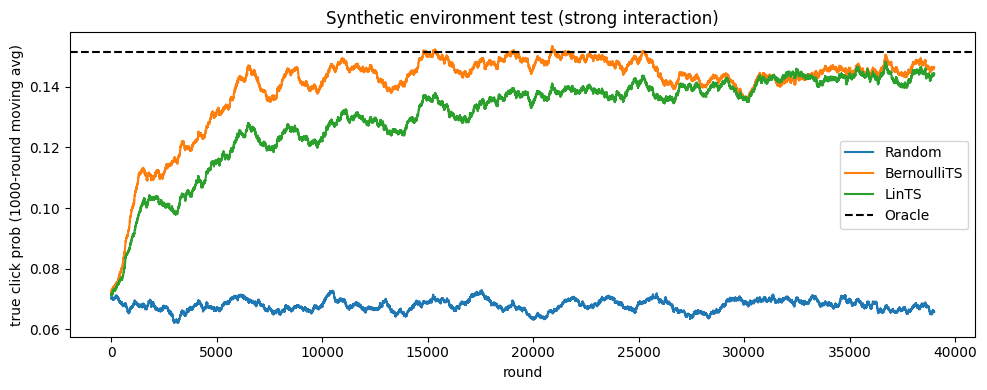

In [5]:
# ===== 정답 가중치 생성 함수 (아이템 효과, 상호작용 효과의 크기를 따로 지정) =====
def make_true_theta(item_scale: float, interaction_scale: float, seed: int) -> np.ndarray:
    theta_rng = np.random.default_rng(seed)
    theta = np.zeros(feature_builder.n_dims)
    item_start = feature_builder.n_user_dims
    interaction_start = item_start + feature_builder.n_item_dims
    theta[item_start:interaction_start] = theta_rng.normal(0, item_scale, feature_builder.n_item_dims)
    theta[interaction_start:] = theta_rng.normal(0, interaction_scale, feature_builder.n_item_dims)
    return theta

# ===== 환경 진단: 그룹별 최적 아이템, 최적(Oracle), 단일 아이템 상한 =====
def diagnose_environment() -> None:
    flagged_share = interaction_flags.mean()
    empty_user = np.zeros(feature_builder.n_user_dims)  # 정답 가중치의 사용자 구간이 0이라 무관
    flagged_probs = true_click_probs(feature_builder.build_candidates(empty_user, 1.0))
    unflagged_probs = true_click_probs(feature_builder.build_candidates(empty_user, 0.0))

    oracle = flagged_share * flagged_probs.max() + (1 - flagged_share) * unflagged_probs.max()
    single_item_ceiling = (flagged_share * flagged_probs + (1 - flagged_share) * unflagged_probs).max()

    print(f"uf0_1 그룹 최적 아이템: {flagged_probs.argmax()} ({flagged_probs.max():.4f})")
    print(f"나머지 그룹 최적 아이템: {unflagged_probs.argmax()} ({unflagged_probs.max():.4f})")
    print(f"Oracle (그룹별 최적): {oracle:.4f}")
    print(f"단일 아이템 상한 (BernoulliTS의 한계): {single_item_ceiling:.4f} (Oracle 대비 {single_item_ceiling / oracle:.1%})")

# ===== 기존 환경 진단 =====
print("[기존 환경]")
diagnose_environment()

# ===== 수정 환경: 상호작용 효과를 크게 → 그룹별 최적 아이템이 달라지도록 =====
true_theta = make_true_theta(item_scale=0.02, interaction_scale=0.08, seed=TEST_SEED)
print("\n[수정 환경]")
diagnose_environment()

# ===== 수정 환경에서 세 정책 재실행 (라운드 수 2배) =====
N_TEST_ROUNDS = 40_000
sampled_rows = test_rng.integers(user_matrix.shape[0], size=N_TEST_ROUNDS)
reward_uniforms = test_rng.random(N_TEST_ROUNDS)

test_policies = {
    "Random": RandomPolicy(n_items, seed=1),
    "BernoulliTS": BernoulliTS(n_items, seed=1),
    "LinTS": LinTS(n_items, feature_builder.n_dims, exploration_scale=0.5, seed=1),
}
test_results = {policy_name: run_synthetic(policy) for policy_name, policy in test_policies.items()}

# ===== 결과 요약 및 학습 곡선 =====
oracle_ctr = test_results["Random"][1][-5000:].mean()
print(f"\n[마지막 5,000라운드]  Oracle: {oracle_ctr:.4f}")
for policy_name, (chosen_true_probs, _) in test_results.items():
    recent_ctr = chosen_true_probs[-5000:].mean()
    print(f"{policy_name:12s}: {recent_ctr:.4f} (Oracle 대비 {recent_ctr / oracle_ctr:.1%})")

fig, axis = plt.subplots(figsize=(10, 4))
for policy_name, (chosen_true_probs, _) in test_results.items():
    moving_avg = np.convolve(chosen_true_probs, np.ones(window) / window, mode="valid")
    axis.plot(moving_avg, label=policy_name)
axis.axhline(oracle_ctr, color="black", linestyle="--", label="Oracle")
axis.set_xlabel("round")
axis.set_ylabel(f"true click prob ({window}-round moving avg)")
axis.set_title("Synthetic environment test (strong interaction)")
axis.legend()
plt.tight_layout()
plt.show()

In [6]:
from bandit import ReplayData, run_repeated, summarize_results

# ===== 기간 분리 (UTC 기준): 조정 11/24~25, 평가 11/26~30 =====
SPLIT_TIME = pl.datetime(2019, 11, 26, time_zone="UTC")
tune_log_df = random_log_df.filter(pl.col("timestamp") < SPLIT_TIME)
eval_log_df = random_log_df.filter(pl.col("timestamp") >= SPLIT_TIME)

tune_data = ReplayData(tune_log_df, feature_builder)
eval_data = ReplayData(eval_log_df, feature_builder)

print("[기간 분리]")
print(f"조정 기간: {tune_data.n_rows:,}행 / 로그 CTR {tune_data.logged_ctr:.4%}")
print(f"평가 기간: {eval_data.n_rows:,}행 / 로그 CTR {eval_data.logged_ctr:.4%}")

# ===== Random 검증: replay CTR이 로그 CTR과 비슷해야 함 =====
print("\n[Random 검증 - 평가 기간, 5회]")
random_results = run_repeated(lambda seed: RandomPolicy(n_items, seed=seed), eval_data, n_runs=5)
random_summary = summarize_results(random_results, "Random")
print(f"replay CTR 평균: {random_summary['ctr_mean']:.4%} (로그 CTR {eval_data.logged_ctr:.4%})")
print(f"평균 일치 라운드: {random_summary['matched_mean']:,.0f} (기대값 {eval_data.n_rows / n_items:,.0f})")

# ===== LinTS 소요 시간 측정 (조정 기간, 1회) =====
print("\n[LinTS 소요 시간 - 조정 기간, 1회]")
lints_timing = run_repeated(
    lambda seed: LinTS(n_items, feature_builder.n_dims, exploration_scale=0.5, seed=seed),
    tune_data, n_runs=1,
)
seconds_per_row = lints_timing[0].elapsed_seconds / tune_data.n_rows
print(f"행당 {seconds_per_row * 1e6:.0f}µs → 평가 기간 1회 예상 {seconds_per_row * eval_data.n_rows:.0f}초")

[기간 분리]
조정 기간: 134,902행 / 로그 CTR 0.5226%
평가 기간: 317,966행 / 로그 CTR 0.4828%

[Random 검증 - 평가 기간, 5회]
  run  1/5: 일치 9,534 / 클릭 58 / CTR 0.6083% (0.4초)
  run  2/5: 일치 9,491 / 클릭 39 / CTR 0.4109% (0.4초)
  run  3/5: 일치 9,329 / 클릭 38 / CTR 0.4073% (0.4초)
  run  4/5: 일치 9,314 / 클릭 41 / CTR 0.4402% (0.4초)
  run  5/5: 일치 9,351 / 클릭 53 / CTR 0.5668% (0.4초)
replay CTR 평균: 0.4867% (로그 CTR 0.4828%)
평균 일치 라운드: 9,404 (기대값 9,352)

[LinTS 소요 시간 - 조정 기간, 1회]
  run  1/1: 일치 3,922 / 클릭 24 / CTR 0.6119% (5.9초)
행당 44µs → 평가 기간 1회 예상 14초


# LinTS 하이퍼파라미터 조정

[exploration_scale = 0.1] 50회 실행 중...
  완료 (225초)
[exploration_scale = 0.5] 50회 실행 중...
  완료 (229초)
[exploration_scale = 1.0] 50회 실행 중...
  완료 (288초)

[조정 결과]
shape: (3, 7)
┌──────────────────┬──────────┬─────────────┬──────────┬───────────┬──────────────┬─────────────┐
│ policy           ┆ ctr_mean ┆ ctr_std_err ┆ ctr_p2.5 ┆ ctr_p97.5 ┆ matched_mean ┆ clicks_mean │
│ ---              ┆ ---      ┆ ---         ┆ ---      ┆ ---       ┆ ---          ┆ ---         │
│ str              ┆ f64      ┆ f64         ┆ f64      ┆ f64       ┆ f64          ┆ f64         │
╞══════════════════╪══════════╪═════════════╪══════════╪═══════════╪══════════════╪═════════════╡
│ LinTS(scale=0.1) ┆ 0.00556  ┆ 0.00021     ┆ 0.003394 ┆ 0.00855   ┆ 3930.46      ┆ 21.86       │
│ LinTS(scale=0.5) ┆ 0.005147 ┆ 0.00017     ┆ 0.003182 ┆ 0.007239  ┆ 3957.3       ┆ 20.36       │
│ LinTS(scale=1.0) ┆ 0.005372 ┆ 0.000162    ┆ 0.002877 ┆ 0.00745   ┆ 3943.98      ┆ 21.18       │
└──────────────────┴──────────┴────────────

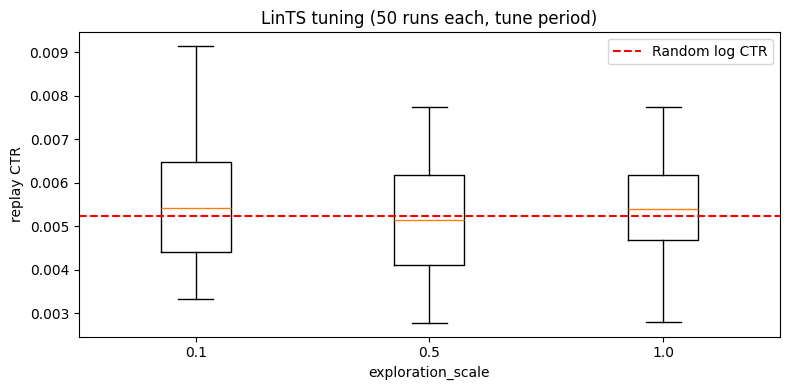

In [7]:
# ===== 조정 설정 =====
EXPLORATION_SCALE_CANDIDATES = [0.1, 0.5, 1.0]
N_TUNE_RUNS = 50
TUNE_BASE_SEED = 100  # 모든 후보가 같은 로그 순서로 실행되도록 고정

# ===== 후보별 반복 실행 (조정 기간) =====
tune_results = {}
for exploration_scale in EXPLORATION_SCALE_CANDIDATES:
    print(f"[exploration_scale = {exploration_scale}] {N_TUNE_RUNS}회 실행 중...")
    tune_results[exploration_scale] = run_repeated(
        lambda seed, scale=exploration_scale: LinTS(n_items, feature_builder.n_dims,
                                                    exploration_scale=scale, seed=seed),
        tune_data, n_runs=N_TUNE_RUNS, base_seed=TUNE_BASE_SEED, verbose=False,
    )
    total_seconds = sum(result.elapsed_seconds for result in tune_results[exploration_scale])
    print(f"  완료 ({total_seconds:.0f}초)")

# ===== 결과 요약: 평균, 표준오차, 95% 구간 =====
tune_summary_rows = []
for exploration_scale, results in tune_results.items():
    summary = summarize_results(results, f"LinTS(scale={exploration_scale})")
    run_ctrs = np.array([result.ctr for result in results])
    summary["ctr_std_err"] = float(run_ctrs.std(ddof=1) / np.sqrt(len(run_ctrs)))
    tune_summary_rows.append(summary)

tune_summary_df = pl.DataFrame(tune_summary_rows).select(
    "policy", "ctr_mean", "ctr_std_err", "ctr_p2.5", "ctr_p97.5", "matched_mean", "clicks_mean"
)
print("\n[조정 결과]")
print(tune_summary_df)
print(f"참고: 조정 기간 로그 CTR(Random) {tune_data.logged_ctr:.4%}")

# ===== 시각화: 후보별 실행 CTR 분포 =====
fig, axis = plt.subplots(figsize=(8, 4))
axis.boxplot(
    [[result.ctr for result in results] for results in tune_results.values()],
    labels=[str(scale) for scale in tune_results.keys()],
)
axis.axhline(tune_data.logged_ctr, color="red", linestyle="--", label="Random log CTR")
axis.set_xlabel("exploration_scale")
axis.set_ylabel("replay CTR")
axis.set_title(f"LinTS tuning ({N_TUNE_RUNS} runs each, tune period)")
axis.legend()
plt.tight_layout()
plt.show()

# LinTS 평가기간 학습

[BernoulliTS]
  완료 (166초)
[LinTS (scale=0.1)]
  완료 (601초)

[평가 결과]
shape: (2, 7)
┌─────────────────┬──────────┬─────────────┬──────────┬───────────┬──────────────┬─────────────┐
│ policy          ┆ ctr_mean ┆ ctr_std_err ┆ ctr_p2.5 ┆ ctr_p97.5 ┆ matched_mean ┆ clicks_mean │
│ ---             ┆ ---      ┆ ---         ┆ ---      ┆ ---       ┆ ---          ┆ ---         │
│ str             ┆ f64      ┆ f64         ┆ f64      ┆ f64       ┆ f64          ┆ f64         │
╞═════════════════╪══════════╪═════════════╪══════════╪═══════════╪══════════════╪═════════════╡
│ BernoulliTS     ┆ 0.004905 ┆ 0.000126    ┆ 0.003635 ┆ 0.006741  ┆ 9372.06      ┆ 45.98       │
│ (replay)        ┆          ┆             ┆          ┆           ┆              ┆             │
│ LinTS scale=0.1 ┆ 0.005124 ┆ 0.000107    ┆ 0.003746 ┆ 0.006789  ┆ 9331.9       ┆ 47.82       │
│ (replay)        ┆          ┆             ┆          ┆           ┆              ┆             │
└─────────────────┴──────────┴─────────────┴──

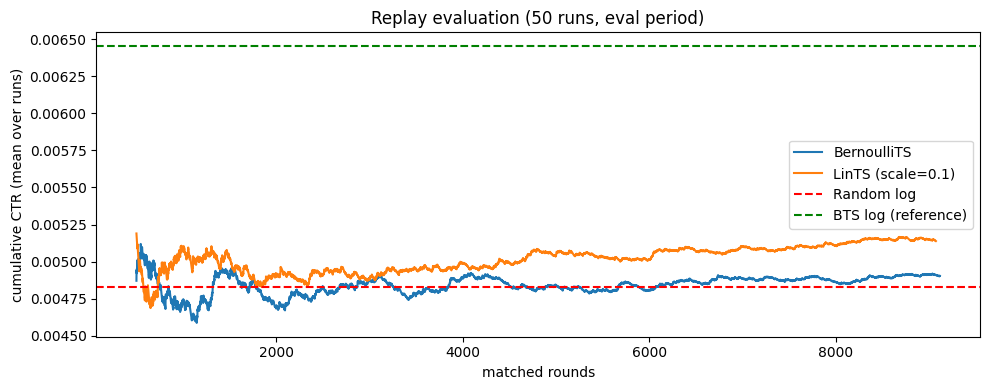

In [8]:
# ===== 평가 설정 =====
SELECTED_SCALE = 0.1   # 조정 결과
N_EVAL_RUNS = 50
EVAL_BASE_SEED = 200   # 조정과 다른 시드, 두 정책은 같은 시드 → 회차별 로그 순서 동일

# ===== 두 정책 반복 실행 (평가 기간) =====
print("[BernoulliTS]")
eval_bts_results = run_repeated(
    lambda seed: BernoulliTS(n_items, seed=seed),
    eval_data, n_runs=N_EVAL_RUNS, base_seed=EVAL_BASE_SEED, verbose=False,
)
print(f"  완료 ({sum(result.elapsed_seconds for result in eval_bts_results):.0f}초)")

print(f"[LinTS (scale={SELECTED_SCALE})]")
eval_lints_results = run_repeated(
    lambda seed: LinTS(n_items, feature_builder.n_dims, exploration_scale=SELECTED_SCALE, seed=seed),
    eval_data, n_runs=N_EVAL_RUNS, base_seed=EVAL_BASE_SEED, verbose=False,
)
print(f"  완료 ({sum(result.elapsed_seconds for result in eval_lints_results):.0f}초)")

# ===== 기준선: 평가 기간의 실제 로그 CTR (Random, BTS) =====
DEDUP_KEY_COLS = ["timestamp", "item_id", "position", "click"]
bts_eval_ctr = (
    pl.scan_csv(DATA_DIR / "bts" / CAMPAIGN / f"{CAMPAIGN}.csv")
    .select(DEDUP_KEY_COLS)
    .unique()
    .with_columns(pl.col("timestamp").str.to_datetime(format="%Y-%m-%d %H:%M:%S%.f%:z"))
    .filter(pl.col("timestamp") >= SPLIT_TIME)
    .select(pl.col("click").mean())
    .collect()
    .item()
)
random_eval_ctr = eval_data.logged_ctr

# ===== 결과 요약표 =====
eval_summary_rows = []
for label, results in [("BernoulliTS (replay)", eval_bts_results),
                       (f"LinTS scale={SELECTED_SCALE} (replay)", eval_lints_results)]:
    summary = summarize_results(results, label)
    run_ctrs = np.array([result.ctr for result in results])
    summary["ctr_std_err"] = float(run_ctrs.std(ddof=1) / np.sqrt(len(run_ctrs)))
    eval_summary_rows.append(summary)

eval_summary_df = pl.DataFrame(eval_summary_rows).select(
    "policy", "ctr_mean", "ctr_std_err", "ctr_p2.5", "ctr_p97.5", "matched_mean", "clicks_mean"
)
print("\n[평가 결과]")
print(eval_summary_df)
print(f"기준선 (평가 기간 실제 로그): Random {random_eval_ctr:.4%} / BTS {bts_eval_ctr:.4%}")

# ===== 회차별 차이 (LinTS − BernoulliTS): 같은 로그 순서끼리 비교 =====
paired_diffs = np.array([
    lints_result.ctr - bts_result.ctr
    for lints_result, bts_result in zip(eval_lints_results, eval_bts_results)
])
print("\n[회차별 차이: LinTS − BernoulliTS]")
print(f"평균 {paired_diffs.mean():+.4%}p / 표준오차 {paired_diffs.std(ddof=1) / np.sqrt(len(paired_diffs)):.4%}p")
print(f"95% 구간 [{np.percentile(paired_diffs, 2.5):+.4%}p, {np.percentile(paired_diffs, 97.5):+.4%}p]")
print(f"LinTS가 더 높았던 회차 비율: {(paired_diffs > 0).mean():.0%}")

# ===== 평균 누적 클릭률 추이 (회차 간 공통 길이까지 평균) =====
BURN_IN = 500  # 초반은 클릭이 몇 건뿐이라 크게 요동치므로 제외
fig, axis = plt.subplots(figsize=(10, 4))
for label, results in [("BernoulliTS", eval_bts_results), (f"LinTS (scale={SELECTED_SCALE})", eval_lints_results)]:
    common_length = min(result.n_matched for result in results)
    mean_curve = np.mean([result.cumulative_ctr[:common_length] for result in results], axis=0)
    axis.plot(np.arange(BURN_IN, common_length), mean_curve[BURN_IN:], label=label)
axis.axhline(random_eval_ctr, color="red", linestyle="--", label="Random log")
axis.axhline(bts_eval_ctr, color="green", linestyle="--", label="BTS log (reference)")
axis.set_xlabel("matched rounds")
axis.set_ylabel("cumulative CTR (mean over runs)")
axis.set_title(f"Replay evaluation ({N_EVAL_RUNS} runs, eval period)")
axis.legend()
plt.tight_layout()
plt.show()